# SL MINI PROJECT :

# Fraud Detection EDA (Exploratory Data Analysis)

## Section : A5
## Names :
### Om Supe | A5-B2-19
### Shriraj Dhore | A5-B1-02
### Sahil Bhure | A5-B2-30

## 1. Imports and Loading Dataset

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv('fraud.csv')
df.shape

(7000, 13)

In [8]:
df.head()

,transaction_amount,hour_of_day,is_weekend,num_items,customer_age,prev_transactions,distance_from_home,device_type,network_quality,is_first_transaction,store_type,velocity_score,is_fraud
0,161.363691,3.0,0.0,2.0,18.000000,2.0,26.539742,1.0,48.403937,0.0,0.0,3.718296,0
1,116.202851,1.0,1.0,4.0,26.285818,2.0,50.714402,NaN,76.144979,0.0,0.0,4.951272,0
2,1.000000,2.0,0.0,5.0,18.000000,NaN,9.467935,0.0,67.600316,0.0,0.0,4.556043,0
3,48.780618,2.0,0.0,3.0,44.471190,NaN,41.077068,0.0,94.825526,0.0,0.0,6.918437,0
4,NaN,3.0,0.0,4.0,38.733609,8.0,NaN,2.0,100.000000,0.0,1.0,5.535335,1


## 2. Analysing Data :

In [9]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   transaction_amount    6440 non-null   float64
 1   hour_of_day           6650 non-null   float64
 2   is_weekend            6860 non-null   float64
 3   num_items             6790 non-null   float64
 4   customer_age          6160 non-null   float64
 5   prev_transactions     6510 non-null   float64
 6   distance_from_home    6300 non-null   float64
 7   device_type           6720 non-null   float64
 8   network_quality       6370 non-null   float64
 9   is_first_transaction  6790 non-null   float64
 10  store_type            6860 non-null   float64
 11  velocity_score        5950 non-null   float64
 12  is_fraud              7000 non-null   int64  
dtypes: float64(12), int64(1)
memory usage: 711.1 KB


,transaction_amount,hour_of_day,is_weekend,num_items,customer_age,prev_transactions,distance_from_home,device_type,network_quality,is_first_transaction,store_type,velocity_score,is_fraud
count,6440.000000,6650.000000,6860.000000,6790.000000,6160.000000,6510.000000,6300.000000,6720.000000,6370.000000,6790.000000,6860.000000,5950.000000,7000.000000
mean,100.014648,2.200902,0.108601,2.977320,36.200811,4.457604,24.830735,0.698810,74.094739,0.095876,0.286735,5.007450,0.103000
std,49.091009,0.677906,0.311160,1.712444,13.283996,4.881635,24.314751,0.776802,18.003855,0.294443,0.452270,2.007633,0.303981
min,1.000000,1.000000,0.000000,0.000000,18.000000,0.000000,0.004282,0.000000,0.477174,0.000000,0.000000,-1.853966,0.000000
25%,65.711569,2.000000,0.000000,2.000000,25.244168,1.000000,7.387315,0.000000,61.586731,0.000000,0.000000,3.697990,0.000000
50%,99.482201,2.000000,0.000000,3.000000,35.361187,3.000000,17.321496,1.000000,75.306346,0.000000,0.000000,4.992099,0.000000
75%,132.897923,3.000000,0.000000,4.000000,45.500089,6.000000,34.857859,1.000000,88.253574,0.000000,1.000000,6.342852,0.000000
max,296.311885,3.000000,1.000000,13.000000,80.000000,40.000000,224.699757,2.000000,100.000000,1.000000,1.000000,12.659564,1.000000


## 3. Checking Null Counts :

In [10]:
null_counts = df.isnull().sum()
print("Missing values count:")
print(null_counts)

Missing values count:
transaction_amount       560
hour_of_day              350
is_weekend               140
num_items                210
customer_age             840
prev_transactions        490
distance_from_home       700
device_type              280
network_quality          630
is_first_transaction     210
store_type               140
velocity_score          1050
is_fraud                   0
dtype: int64


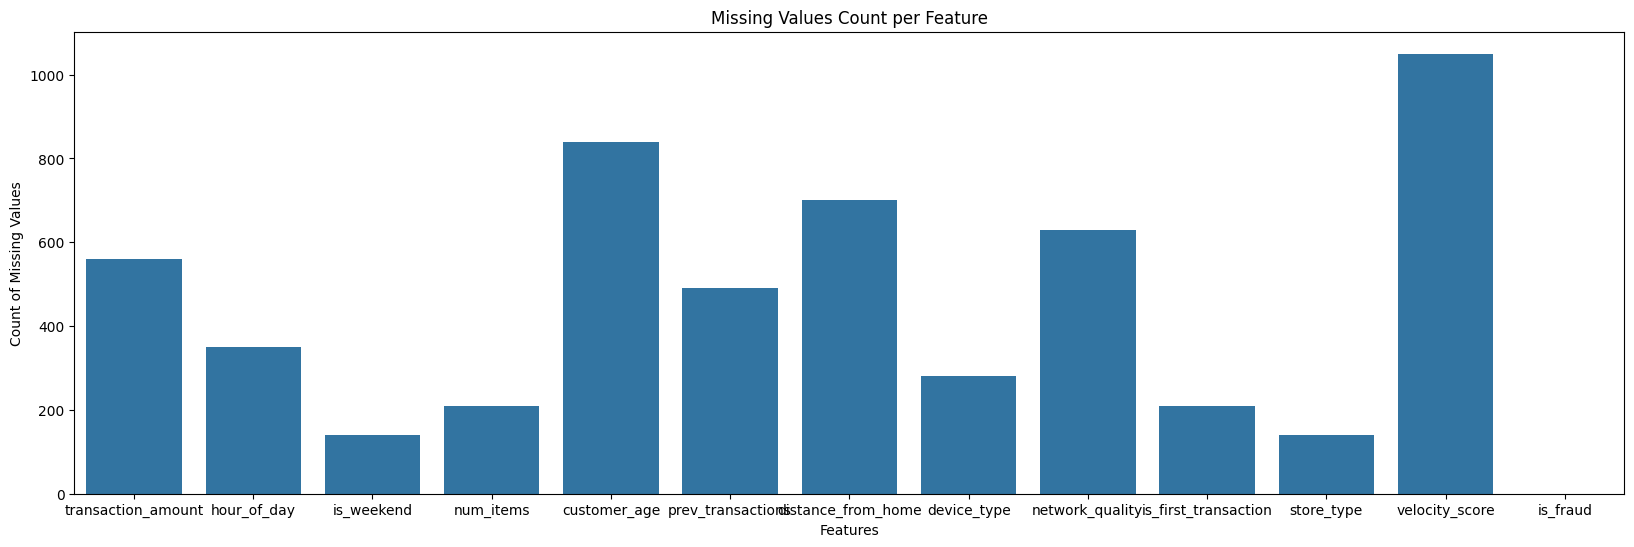

In [11]:
plt.figure(figsize=(20, 6))
sns.barplot(x=null_counts.index, y=null_counts.values)
plt.title('Missing Values Count per Feature')
plt.xlabel('Features')
plt.ylabel('Count of Missing Values')
plt.show()

## 4. Adding Values to null Values :

In [12]:
df_clean = df.copy()
num_cols = ['transaction_amount', 'customer_age', 'prev_transactions',
            'distance_from_home', 'network_quality', 'velocity_score']
cat_cols = ['hour_of_day', 'is_weekend', 'device_type',
            'is_first_transaction', 'store_type', 'num_items']

In [13]:
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])
print("Total missing values after cleaning:", df_clean.isnull().sum().sum())

Total missing values after cleaning: 0


## 5. Searching and fixing Outliers :

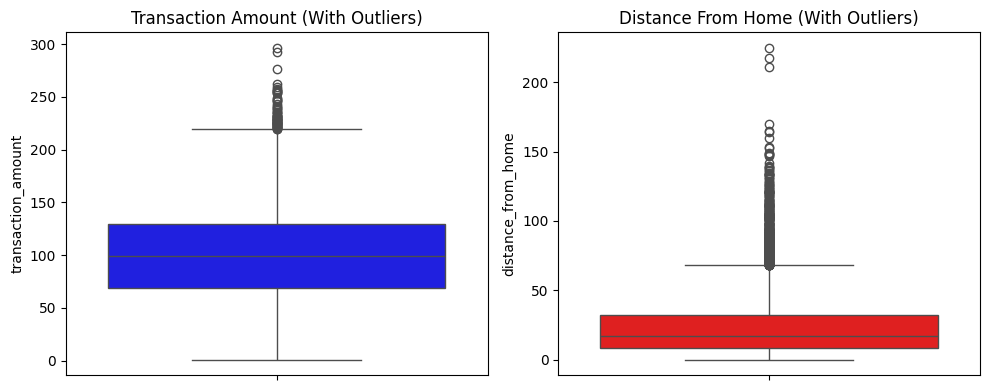

In [14]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=df_clean['transaction_amount'], color='blue')
plt.title('Transaction Amount (With Outliers)')

plt.subplot(1, 2, 2)
sns.boxplot(y=df_clean['distance_from_home'], color='red')
plt.title('Distance From Home (With Outliers)')

plt.tight_layout()
plt.show()

In [15]:
features_with_outliers = [
    'transaction_amount', 'customer_age', 'prev_transactions',
    'distance_from_home', 'network_quality', 'velocity_score', 'num_items'
]
for col in features_with_outliers:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    df_clean[col] = df_clean[col].clip(lower=lower_bound, upper=upper_bound)

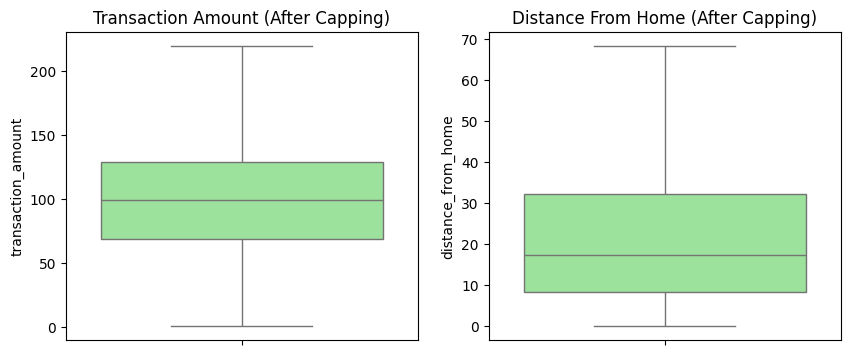

In [16]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=df_clean['transaction_amount'], color='lightgreen')
plt.title('Transaction Amount (After Capping)')

plt.subplot(1, 2, 2)
sns.boxplot(y=df_clean['distance_from_home'], color='lightgreen')
plt.title('Distance From Home (After Capping)')
plt.show()

## 6. Normalising Data :

In [17]:
df_normalized = df_clean.copy()
feature_columns = [col for col in df_normalized.columns if col != 'is_fraud']

for col in feature_columns:
    col_min = df_normalized[col].min()
    col_max = df_normalized[col].max()
    df_normalized[col] = (df_normalized[col] - col_min) / (col_max - col_min)

df_normalized.head()

,transaction_amount,hour_of_day,is_weekend,num_items,customer_age,prev_transactions,distance_from_home,device_type,network_quality,is_first_transaction,store_type,velocity_score,is_fraud
0,0.733646,1.0,0.0,0.285714,0.000000,0.148148,0.388936,0.5,0.292648,0.0,0.0,0.348958,0
1,0.527040,0.0,1.0,0.571429,0.161652,0.148148,0.743269,0.0,0.672962,0.0,0.0,0.493170,0
2,0.000000,0.5,0.0,0.714286,0.000000,0.222222,0.138711,0.0,0.555819,0.0,0.0,0.446943,0
3,0.218591,0.5,0.0,0.428571,0.516440,0.222222,0.602012,0.0,0.929061,0.0,0.0,0.723254,0
4,0.450545,1.0,0.0,0.571429,0.404502,0.592593,0.253822,1.0,1.000000,0.0,1.0,0.561483,1


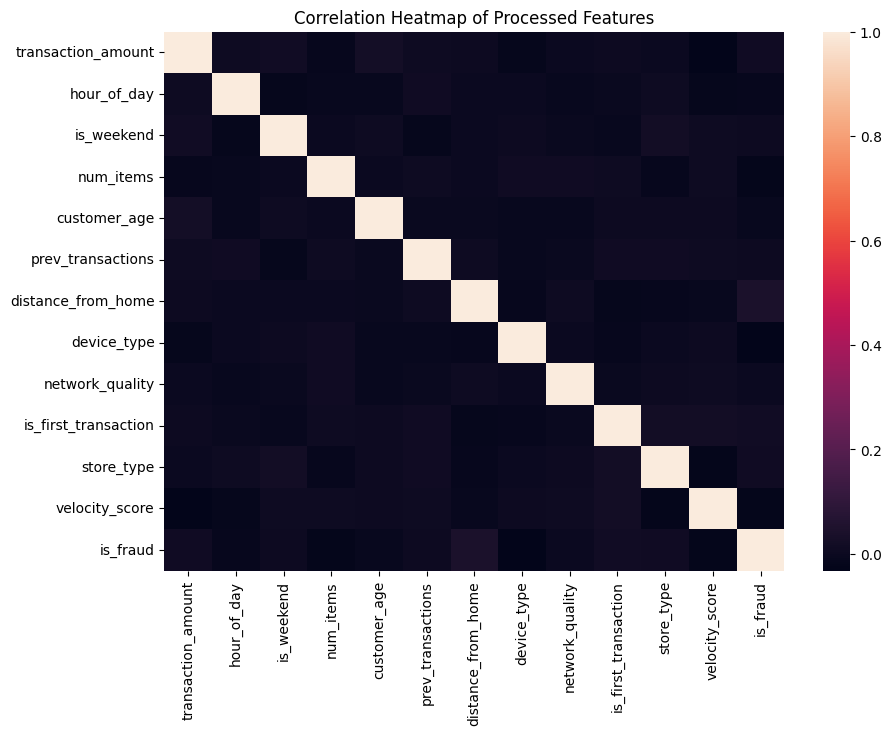

In [18]:
plt.figure(figsize=(10, 7))
sns.heatmap(df_normalized.corr(), cbar=True)
plt.title('Correlation Heatmap of Processed Features')
plt.show()

## 7. Model Building (Logistic Regression)

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

X = df_normalized.drop(columns=['is_fraud'])
y = df_normalized['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (5600, 12)
Testing set shape: (1400, 12)


## 8. Training Model

In [20]:
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 89.36%


## Classifiaction Report :

In [21]:
# Print Confusion Matrix and Classification Report
print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred))

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

--- Confusion Matrix ---
[[1251    0]
 [ 149    0]]

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.89      1.00      0.94      1251
           1       0.00      0.00      0.00       149

    accuracy                           0.89      1400
   macro avg       0.45      0.50      0.47      1400
weighted avg       0.80      0.89      0.84      1400



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## 9. Visualizing Model Performance

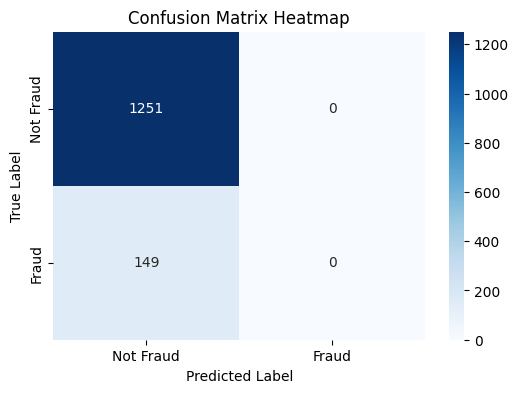

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

# Plotting Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Fraud', 'Fraud'], yticklabels=['Not Fraud', 'Fraud'])
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

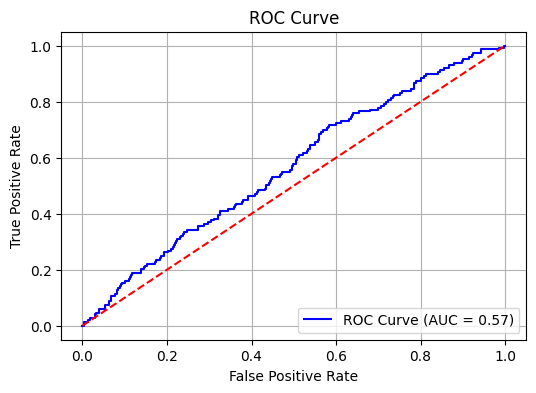

In [23]:
# Plotting ROC Curve
y_pred_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
auc_score = roc_auc_score(y_test, y_pred_prob)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()